In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder,StandardScaler,OneHotEncoder
from sklearn.feature_selection import chi2
from sklearn.model_selection import train_test_split,cross_val_score,GridSearchCV
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,ConfusionMatrixDisplay,classification_report,roc_curve, roc_auc_score

In [2]:
df=pd.read_csv('data.csv')

In [3]:
df.shape

(569, 33)

In [4]:
df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [5]:
df.tail()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,NaN
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,NaN
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,NaN
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,NaN
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,NaN


In [6]:
df.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.isnull().sum()

id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fractal_dimension_worst      0
Unnamed:

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
#EDA before cleaning

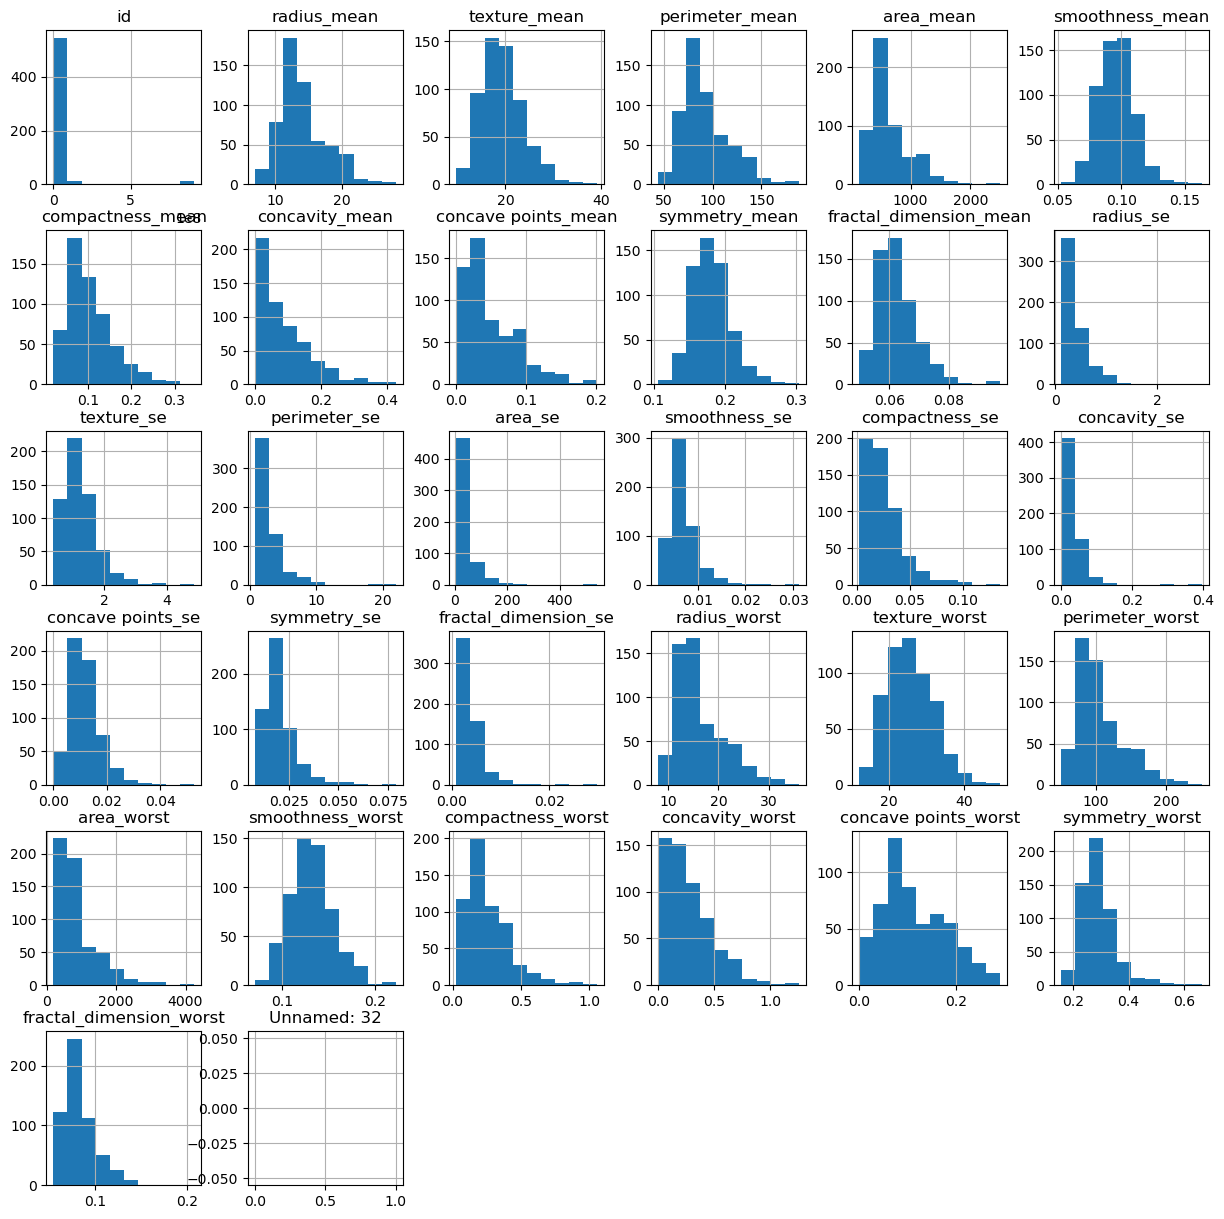

In [11]:
df.hist(figsize=(15,15))
plt.show()

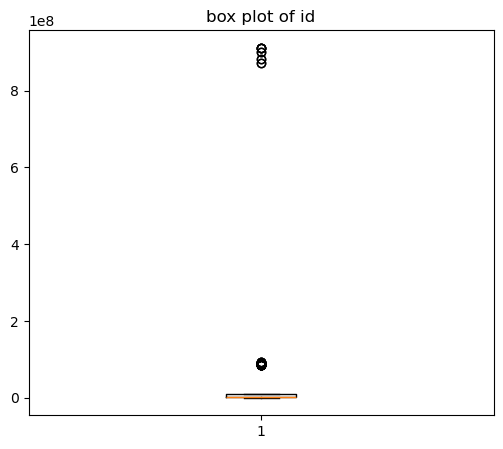

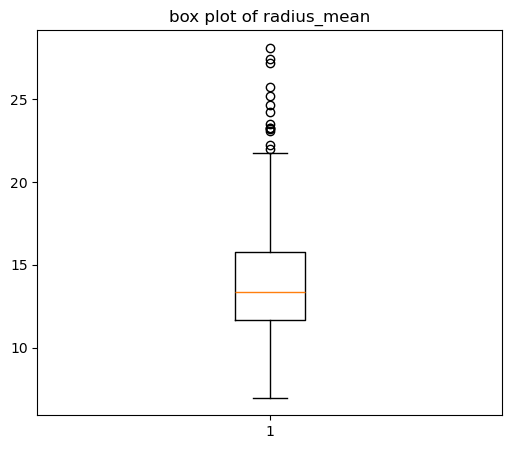

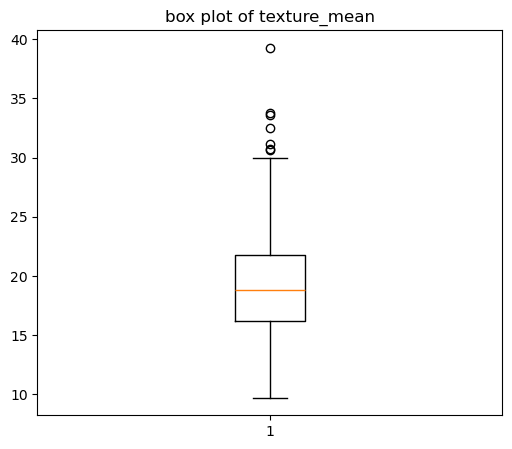

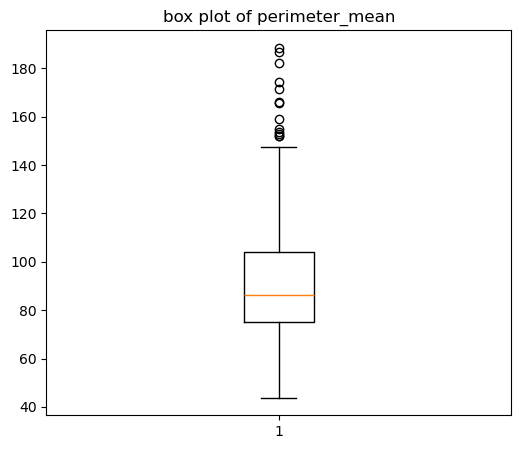

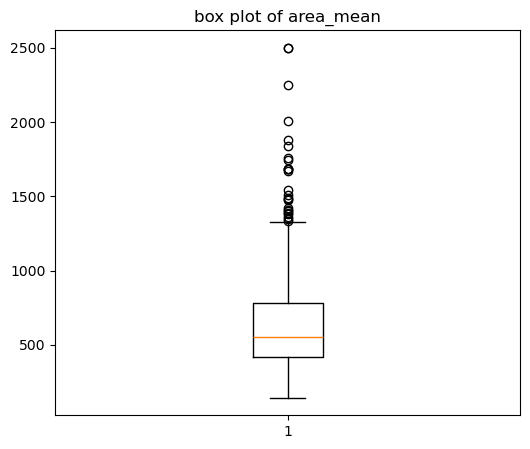

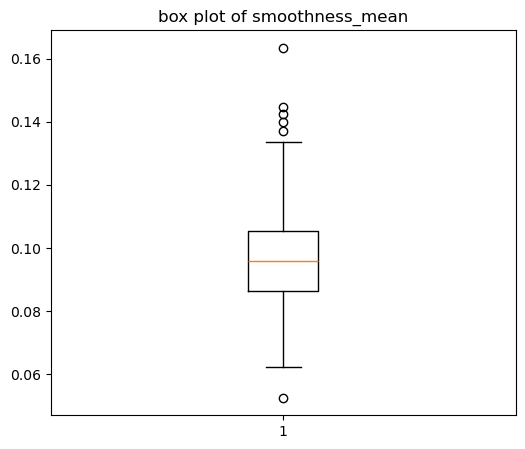

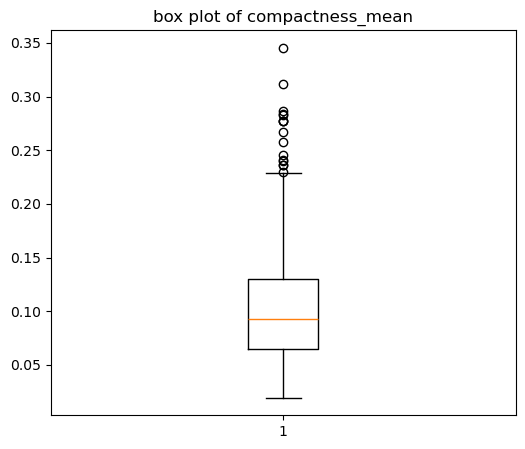

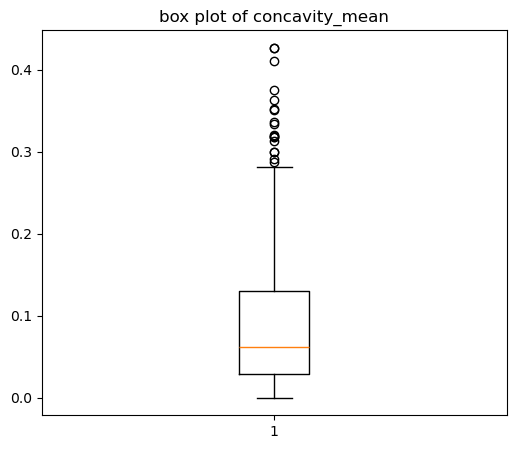

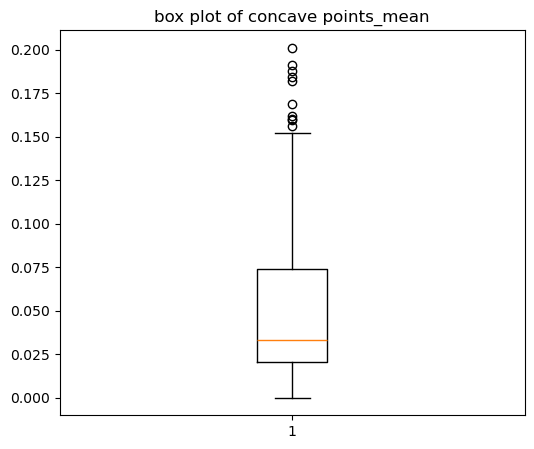

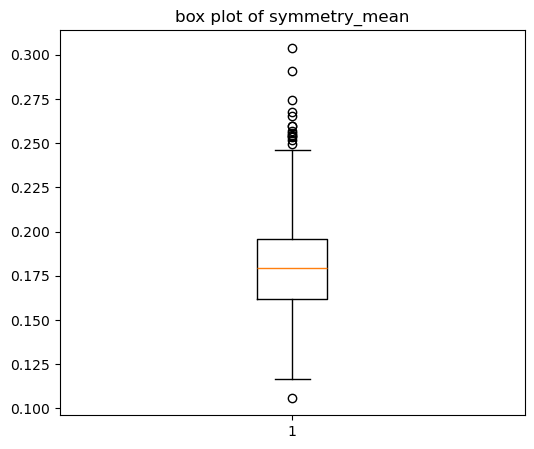

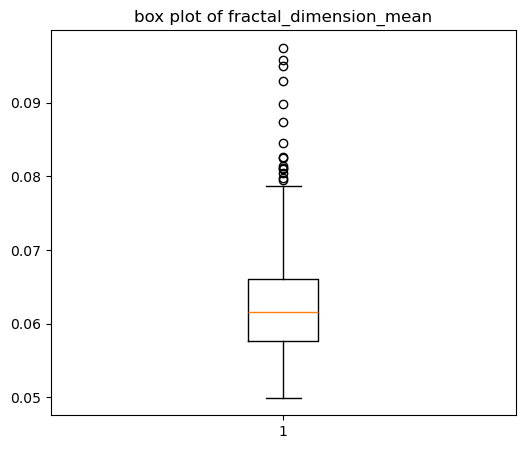

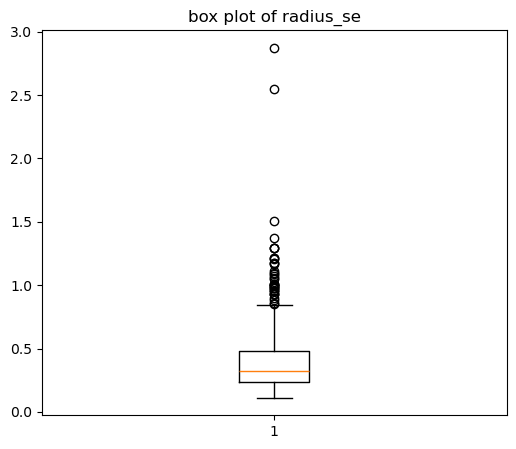

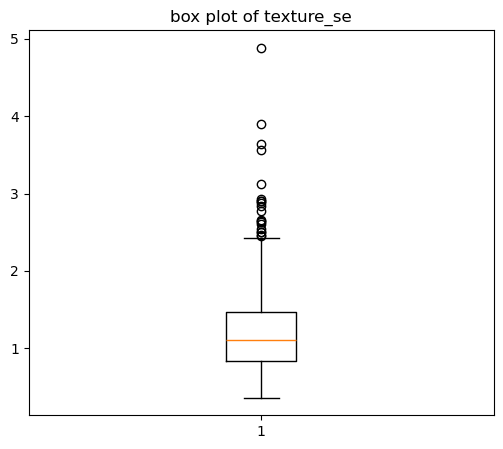

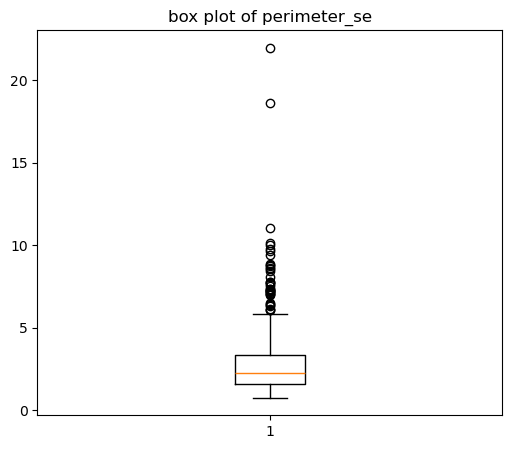

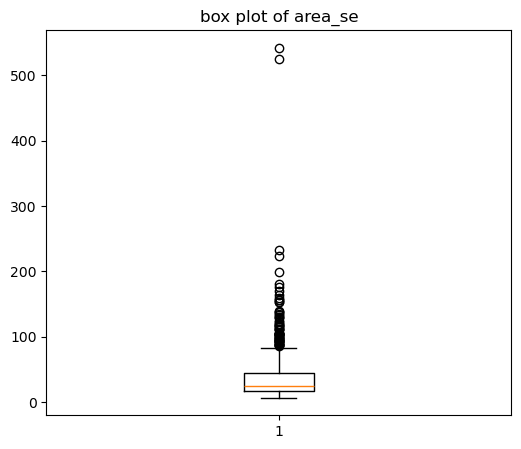

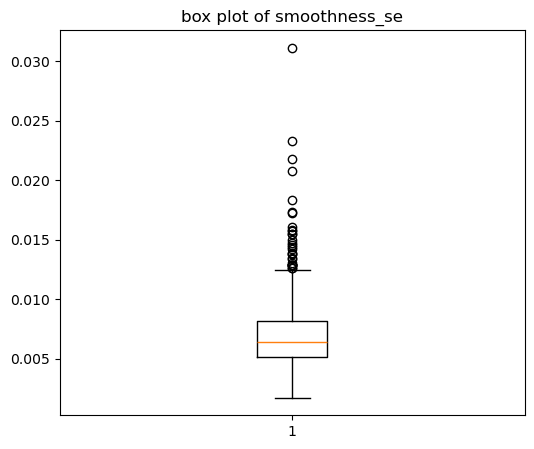

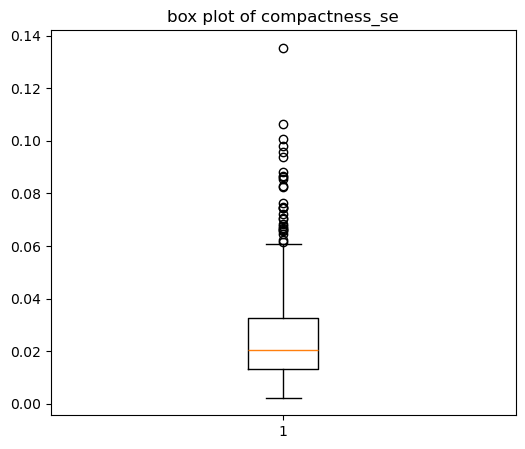

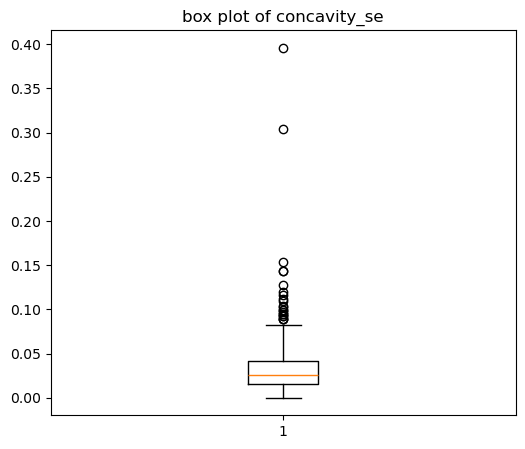

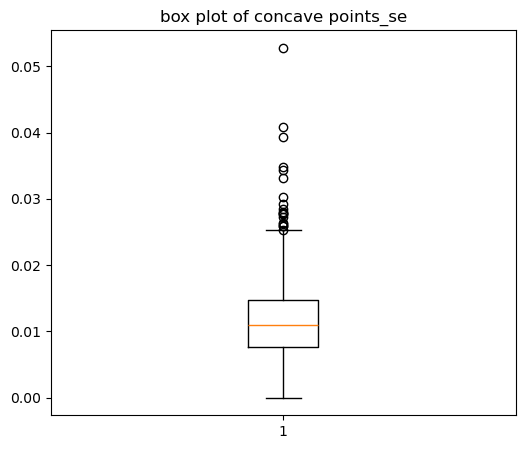

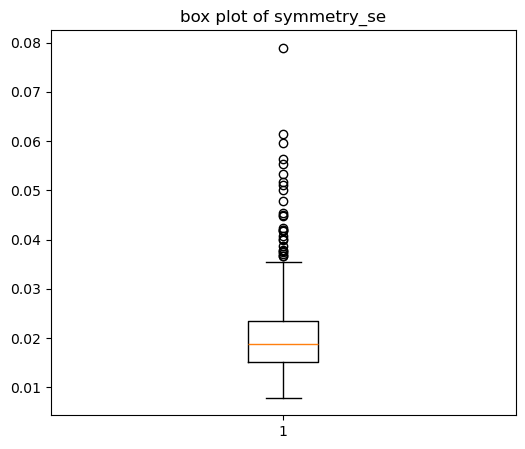

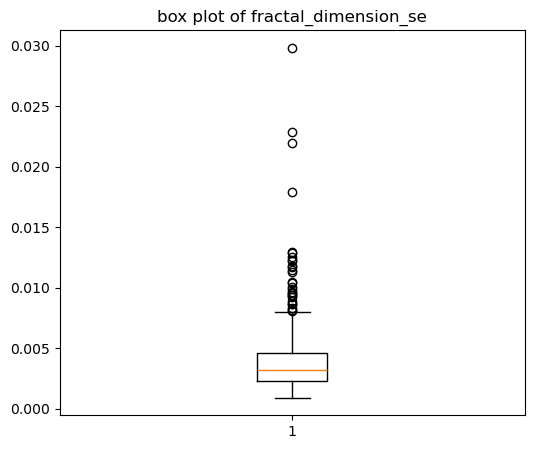

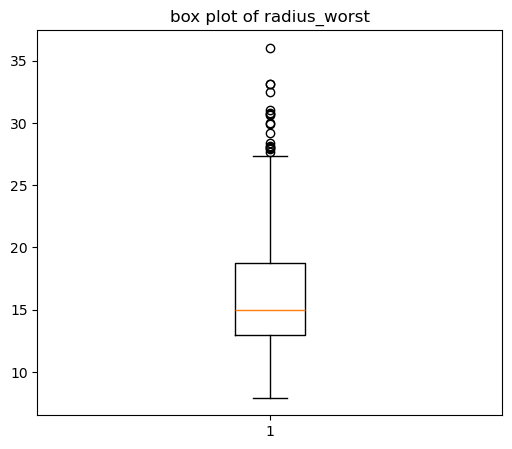

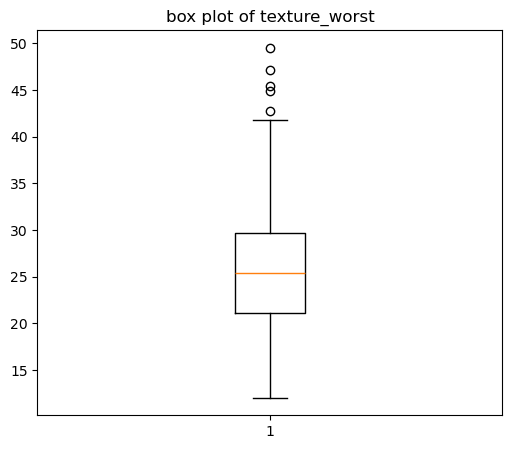

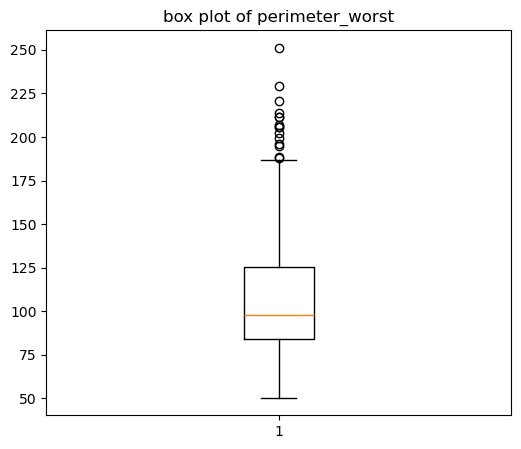

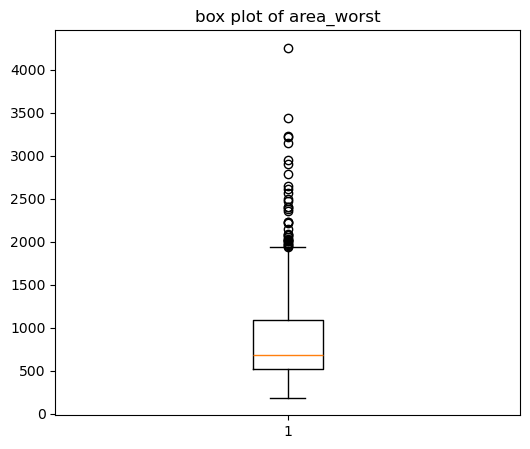

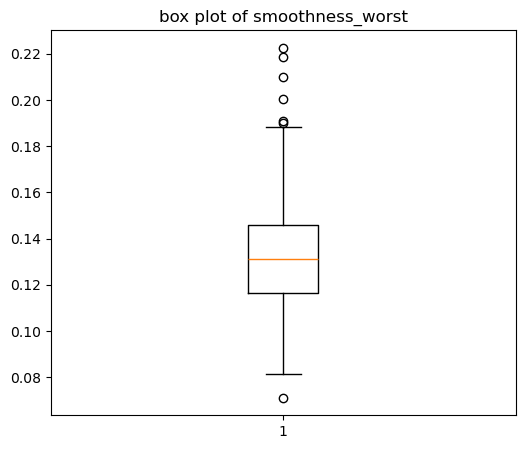

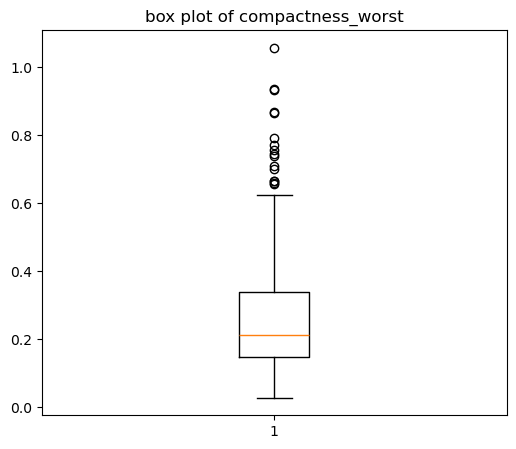

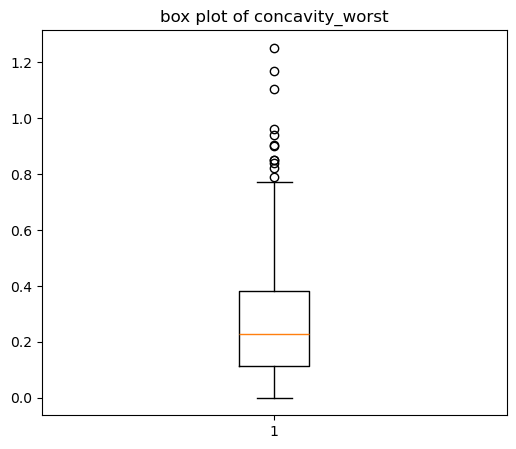

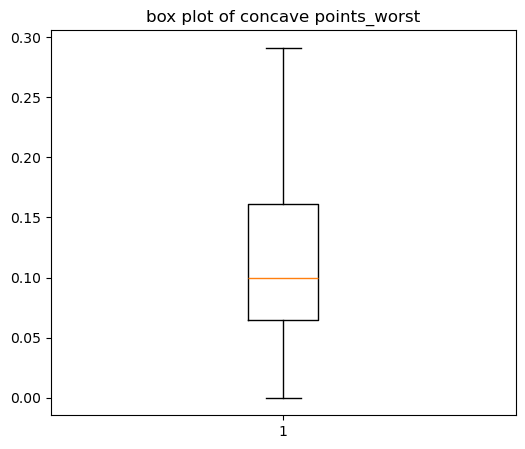

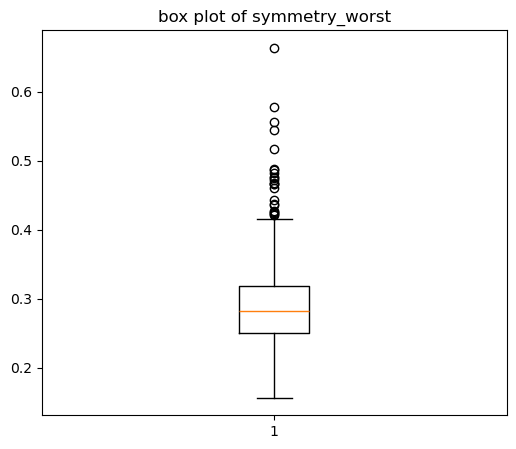

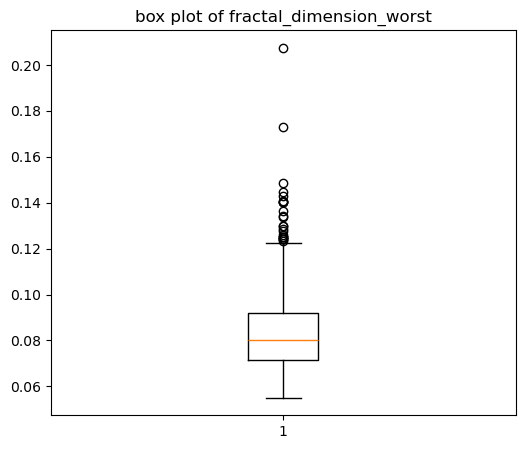

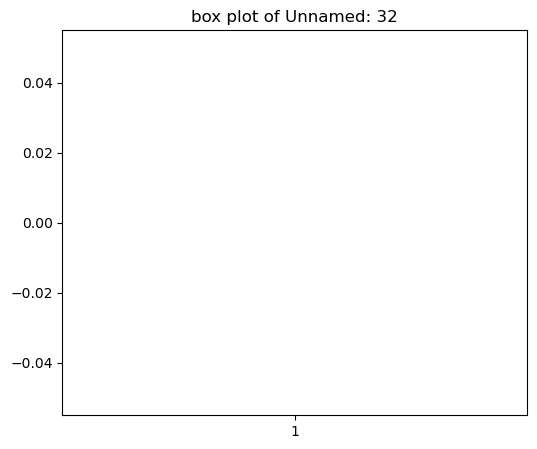

In [12]:
#boxplots
num_cols=df.select_dtypes(include='number').columns
for i in num_cols:
    plt.figure(figsize=(6,5))
    plt.boxplot(df[i])
    plt.title(f"box plot of {i}")
    plt.show()

In [13]:
#data cleaning

In [14]:
#cleaning null values
df=df.drop(['Unnamed: 32'],axis=1)

In [15]:
#treating outliers
num_cols=df.select_dtypes(include='number').columns
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    df[col]=df[col].clip(lower_limit,upper_limit)

In [16]:
#removing unwanted columns
df=df.drop(['id'],axis=1)

In [17]:
#EDA after data cleaning

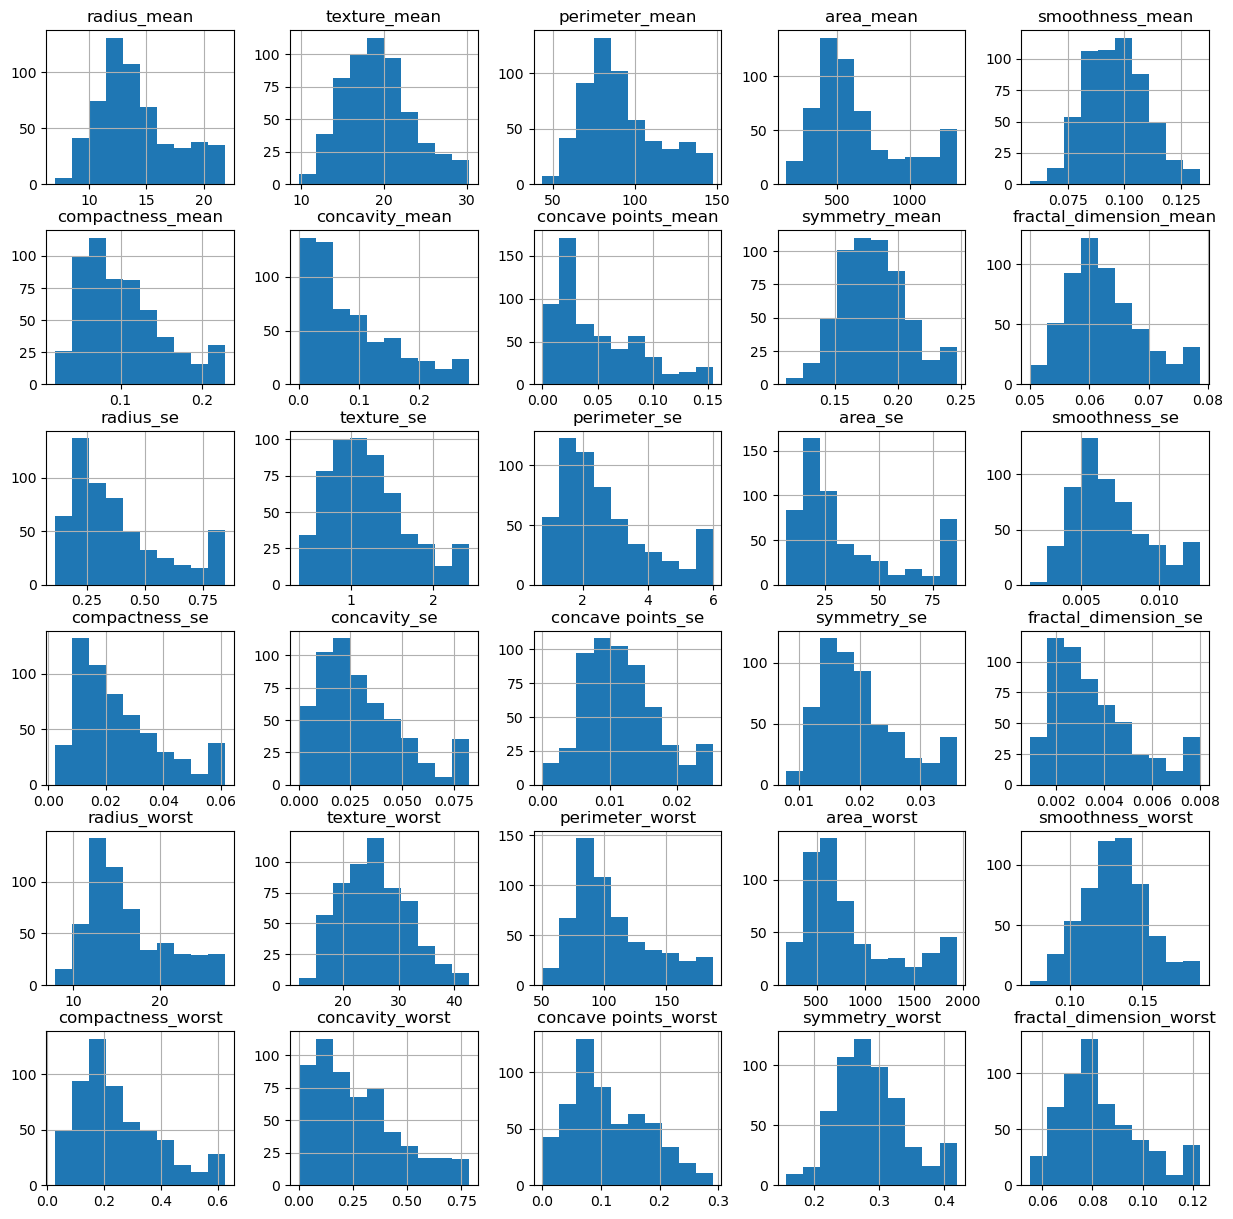

In [18]:
df.hist(figsize=(15,15))
plt.show()

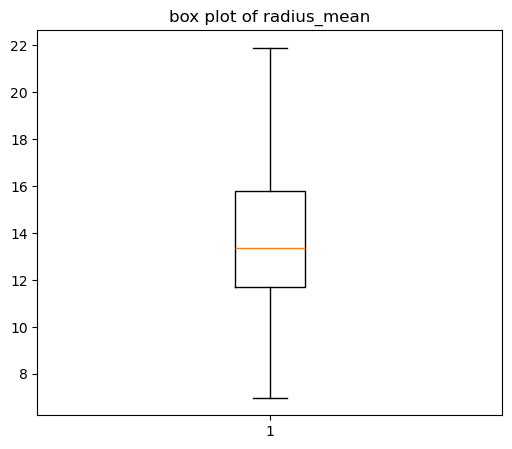

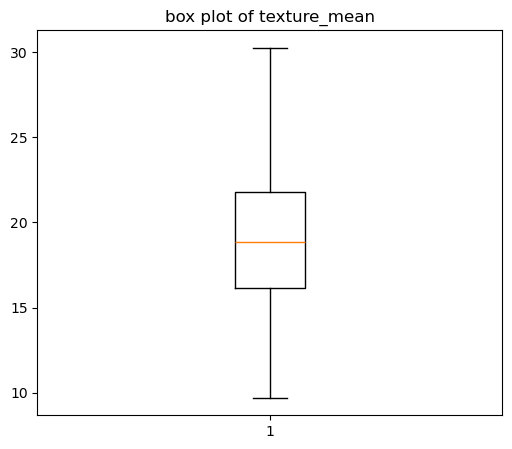

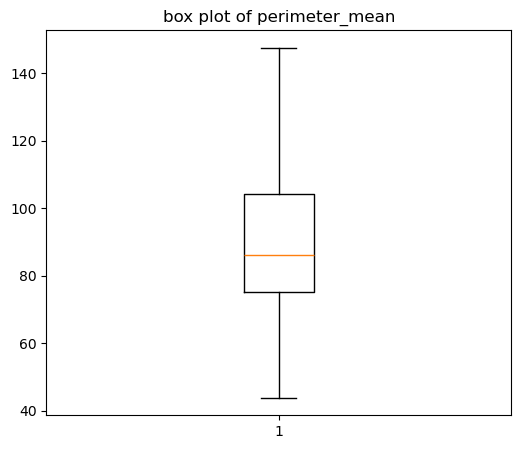

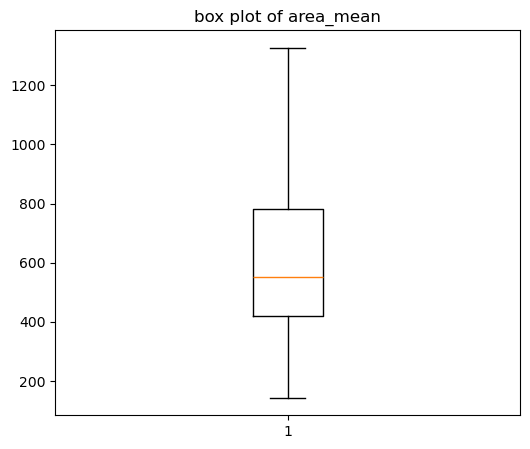

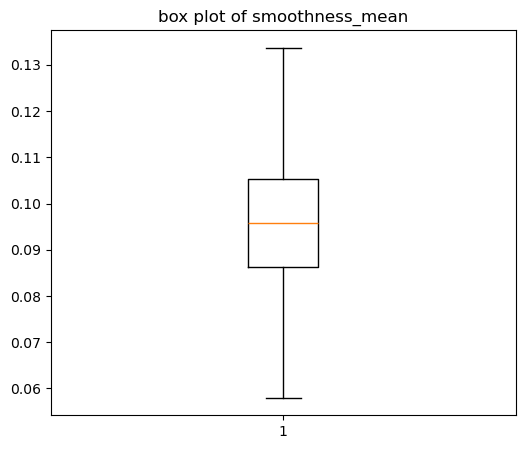

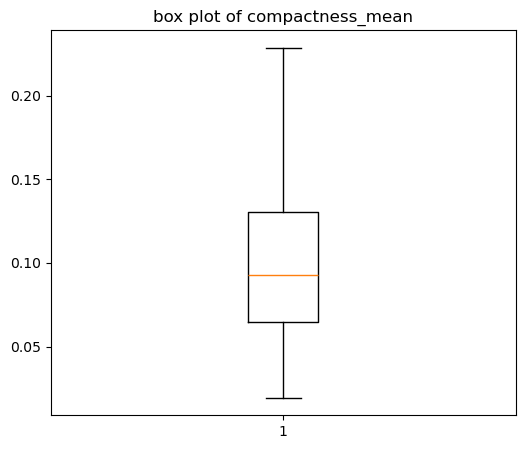

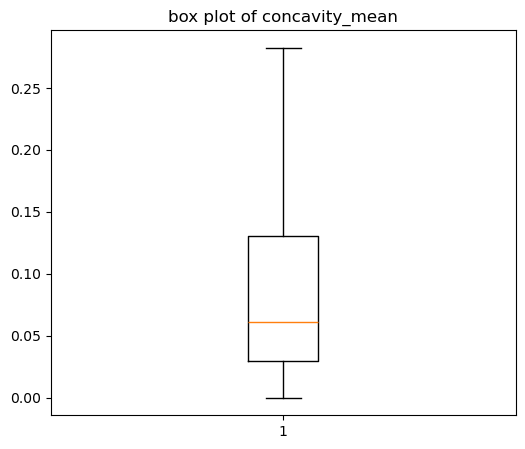

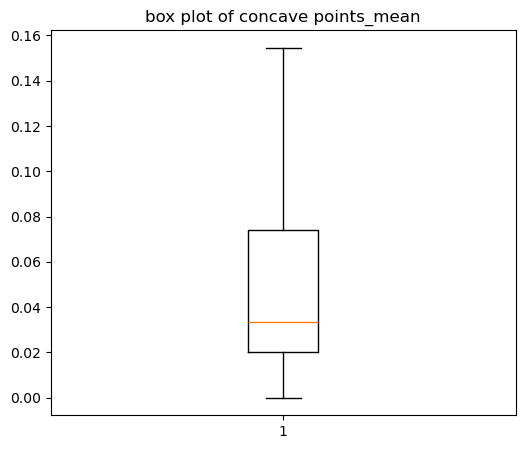

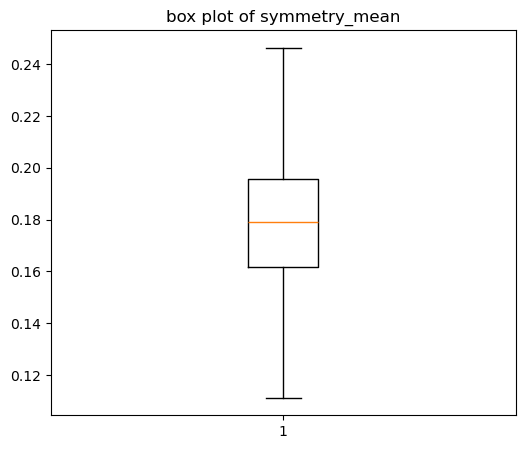

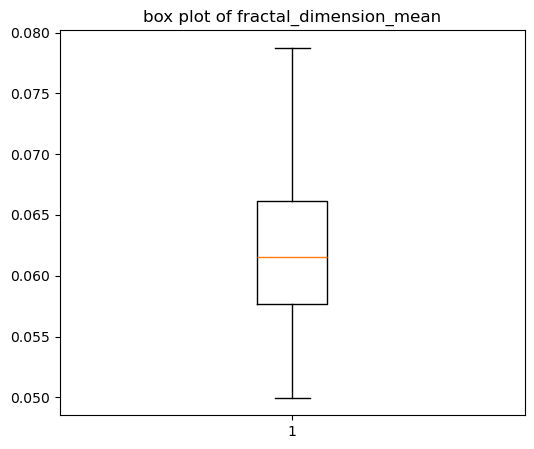

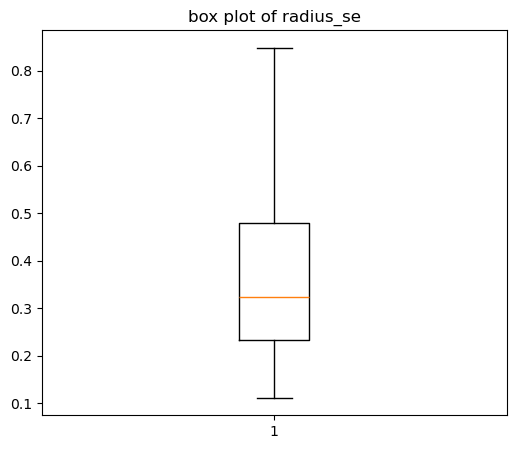

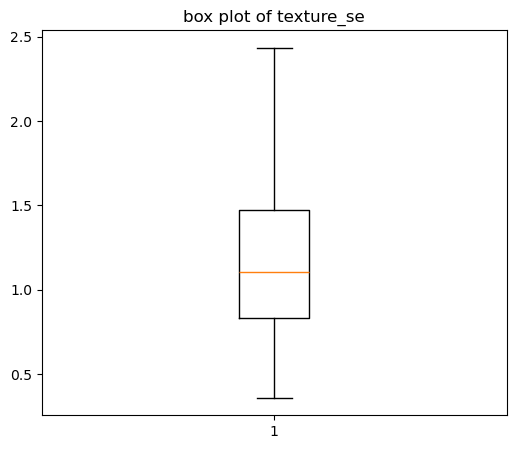

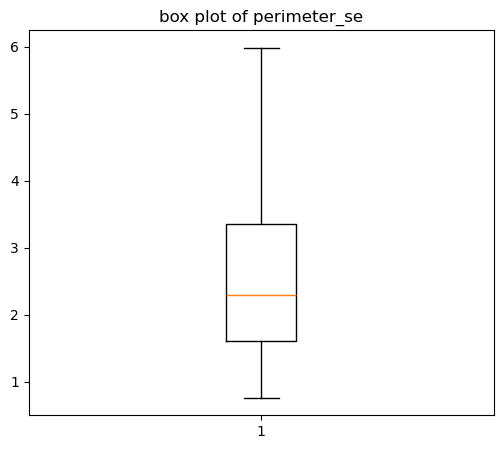

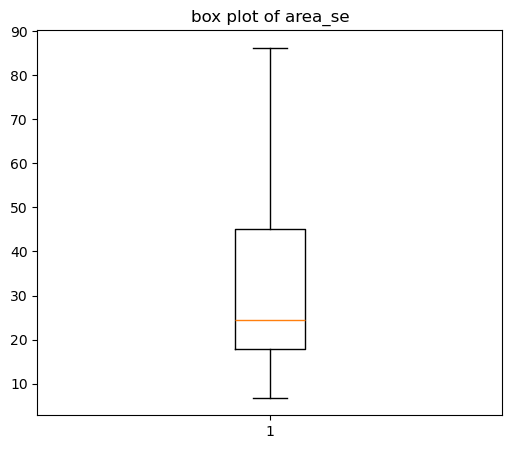

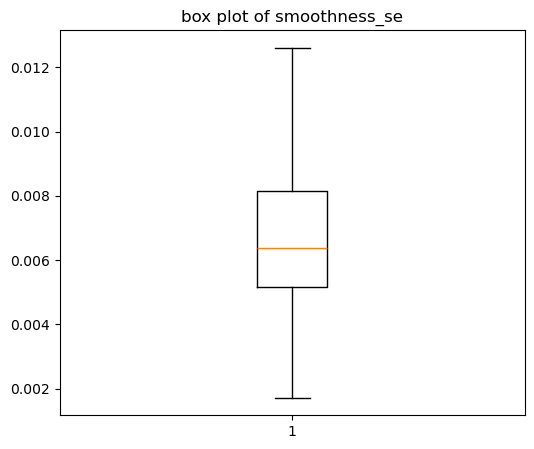

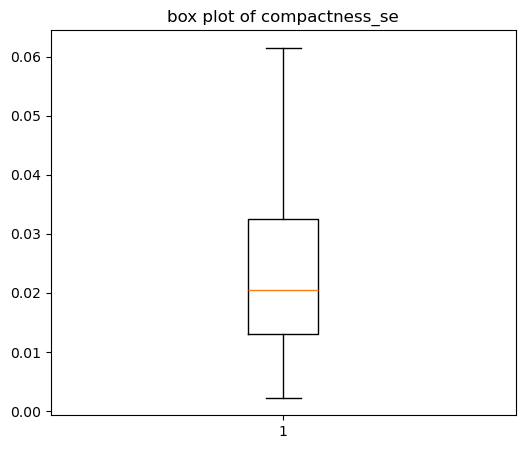

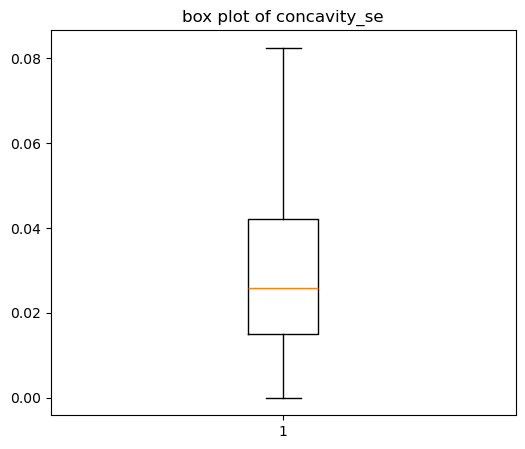

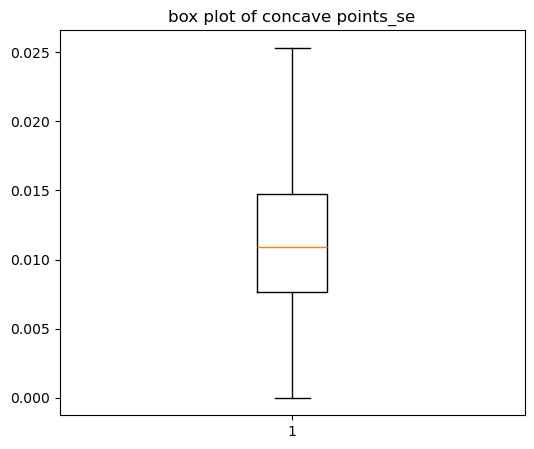

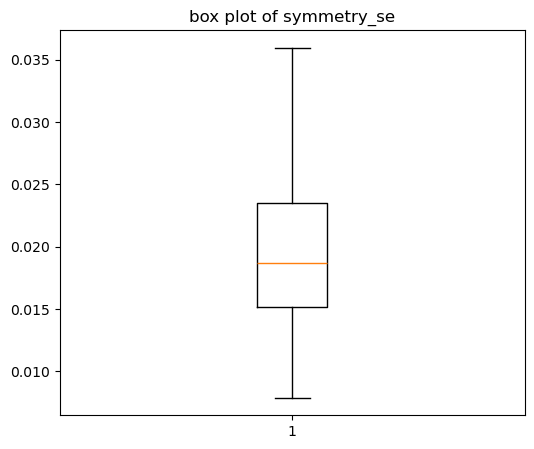

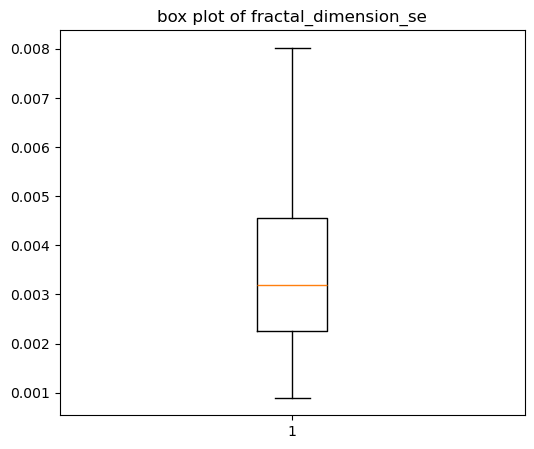

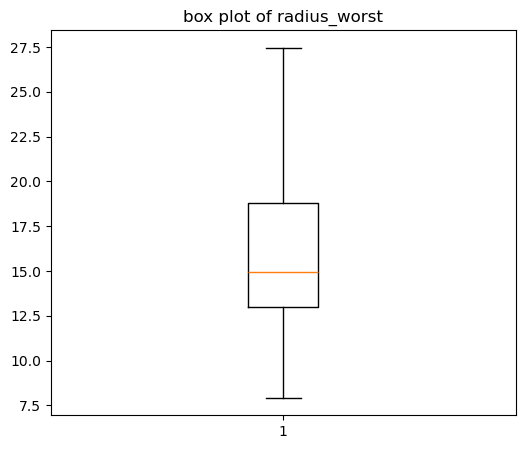

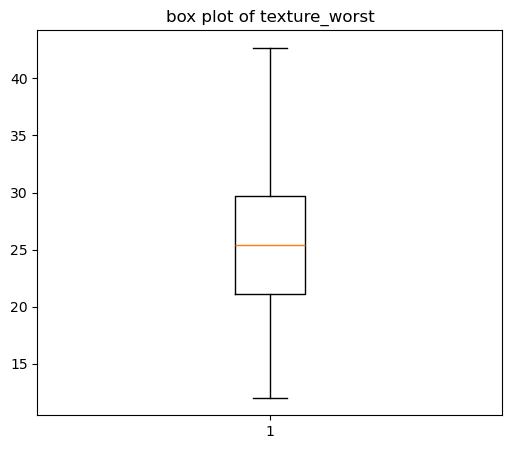

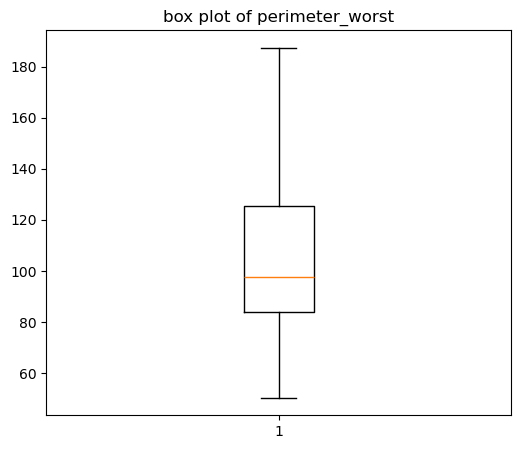

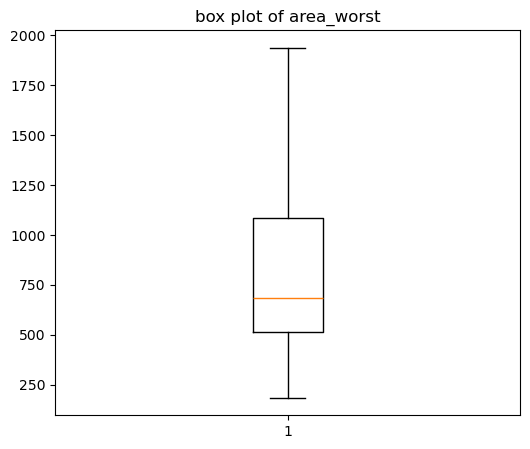

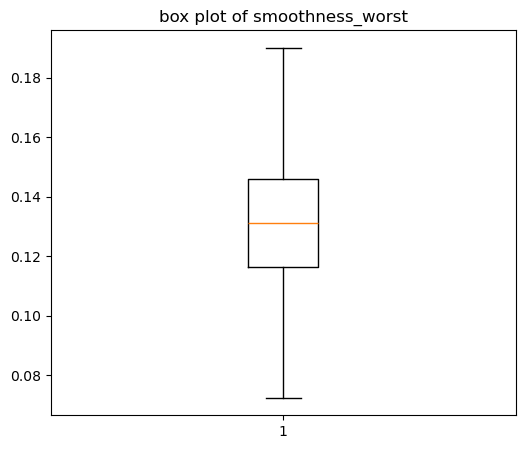

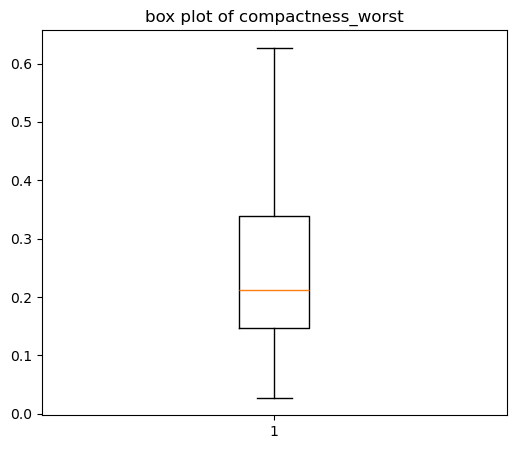

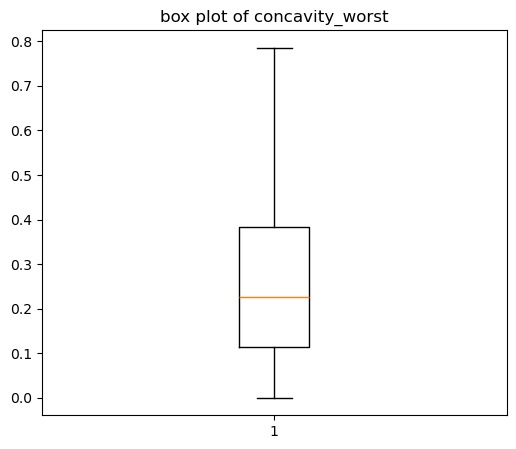

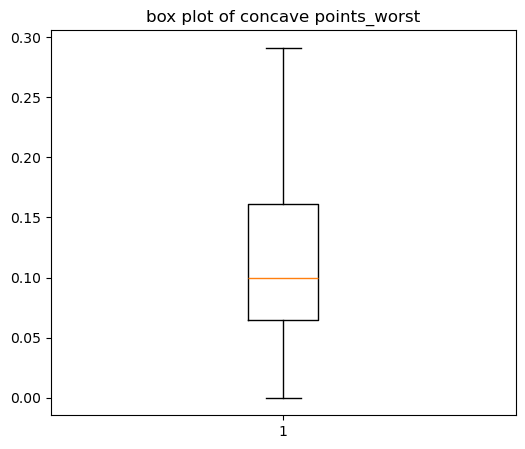

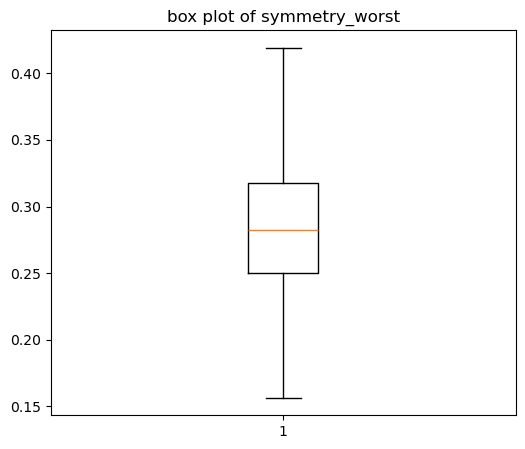

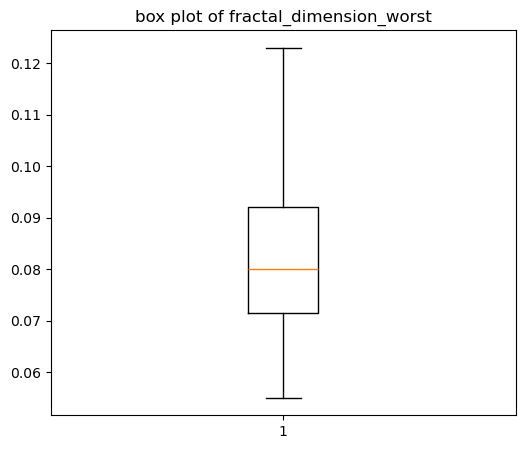

In [19]:
#boxplots
num_cols=df.select_dtypes(include='number').columns
for i in num_cols:
    plt.figure(figsize=(6,5))
    plt.boxplot(df[i])
    plt.title(f"box plot of {i}")
    plt.show()

In [20]:
le = LabelEncoder()
df["diagnosis"] = le.fit_transform(df["diagnosis"])

In [21]:
df['diagnosis'].unique

<bound method Series.unique of 0      1
1      1
2      1
3      1
4      1
      ..
564    1
565    1
566    1
567    1
568    0
Name: diagnosis, Length: 569, dtype: int64>

In [22]:
print(le.classes_)

['B' 'M']


In [23]:
#Feature selection

In [24]:
df.corr()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
diagnosis,1.000000,0.745217,0.419123,0.759006,0.752786,0.366931,0.608494,0.727168,0.788099,0.334536,...,0.793938,0.457663,0.800618,0.794640,0.423390,0.611083,0.683565,0.793566,0.419058,0.328719
radius_mean,0.745217,1.000000,0.332760,0.997692,0.993891,0.167672,0.502741,0.674539,0.811833,0.146763,...,0.973472,0.306225,0.967506,0.962549,0.126332,0.452062,0.559312,0.747817,0.187429,0.028799
texture_mean,0.419123,0.332760,1.000000,0.339588,0.341552,-0.015997,0.241666,0.318654,0.301509,0.079586,...,0.355583,0.911642,0.364127,0.357193,0.077224,0.276731,0.308860,0.296948,0.108611,0.113049
perimeter_mean,0.759006,0.997692,0.339588,1.000000,0.991861,0.204990,0.553698,0.714624,0.841871,0.181325,...,0.974555,0.312741,0.973889,0.963900,0.157912,0.496387,0.597326,0.776769,0.212299,0.075825
area_mean,0.752786,0.993891,0.341552,0.991861,1.000000,0.167400,0.498665,0.680126,0.814133,0.155152,...,0.973784,0.311537,0.967206,0.973460,0.133605,0.441642,0.556230,0.739618,0.185220,0.033012
smoothness_mean,0.366931,0.167672,-0.015997,0.204990,0.167400,1.000000,0.661938,0.526544,0.560961,0.557597,...,0.222464,0.044550,0.246572,0.222205,0.808981,0.482407,0.446253,0.510949,0.403159,0.504675
compactness_mean,0.608494,0.502741,0.241666,0.553698,0.498665,0.661938,1.000000,0.889882,0.832541,0.588842,...,0.542776,0.250386,0.593643,0.537159,0.570701,0.883162,0.835009,0.824531,0.496061,0.710169
concavity_mean,0.727168,0.674539,0.318654,0.714624,0.680126,0.526544,0.889882,1.000000,0.928382,0.489029,...,0.702115,0.316653,0.739514,0.703992,0.462648,0.795115,0.904529,0.881502,0.414279,0.546332
concave points_mean,0.788099,0.811833,0.301509,0.841871,0.814133,0.560961,0.832541,0.928382,1.000000,0.460386,...,0.832188,0.298107,0.855906,0.830127,0.460018,0.701609,0.781051,0.916542,0.384190,0.396626
symmetry_mean,0.334536,0.146763,0.079586,0.181325,0.155152,0.557597,0.588842,0.489029,0.460386,1.000000,...,0.191455,0.099704,0.222826,0.199919,0.431536,0.478419,0.441445,0.430649,0.707566,0.451494


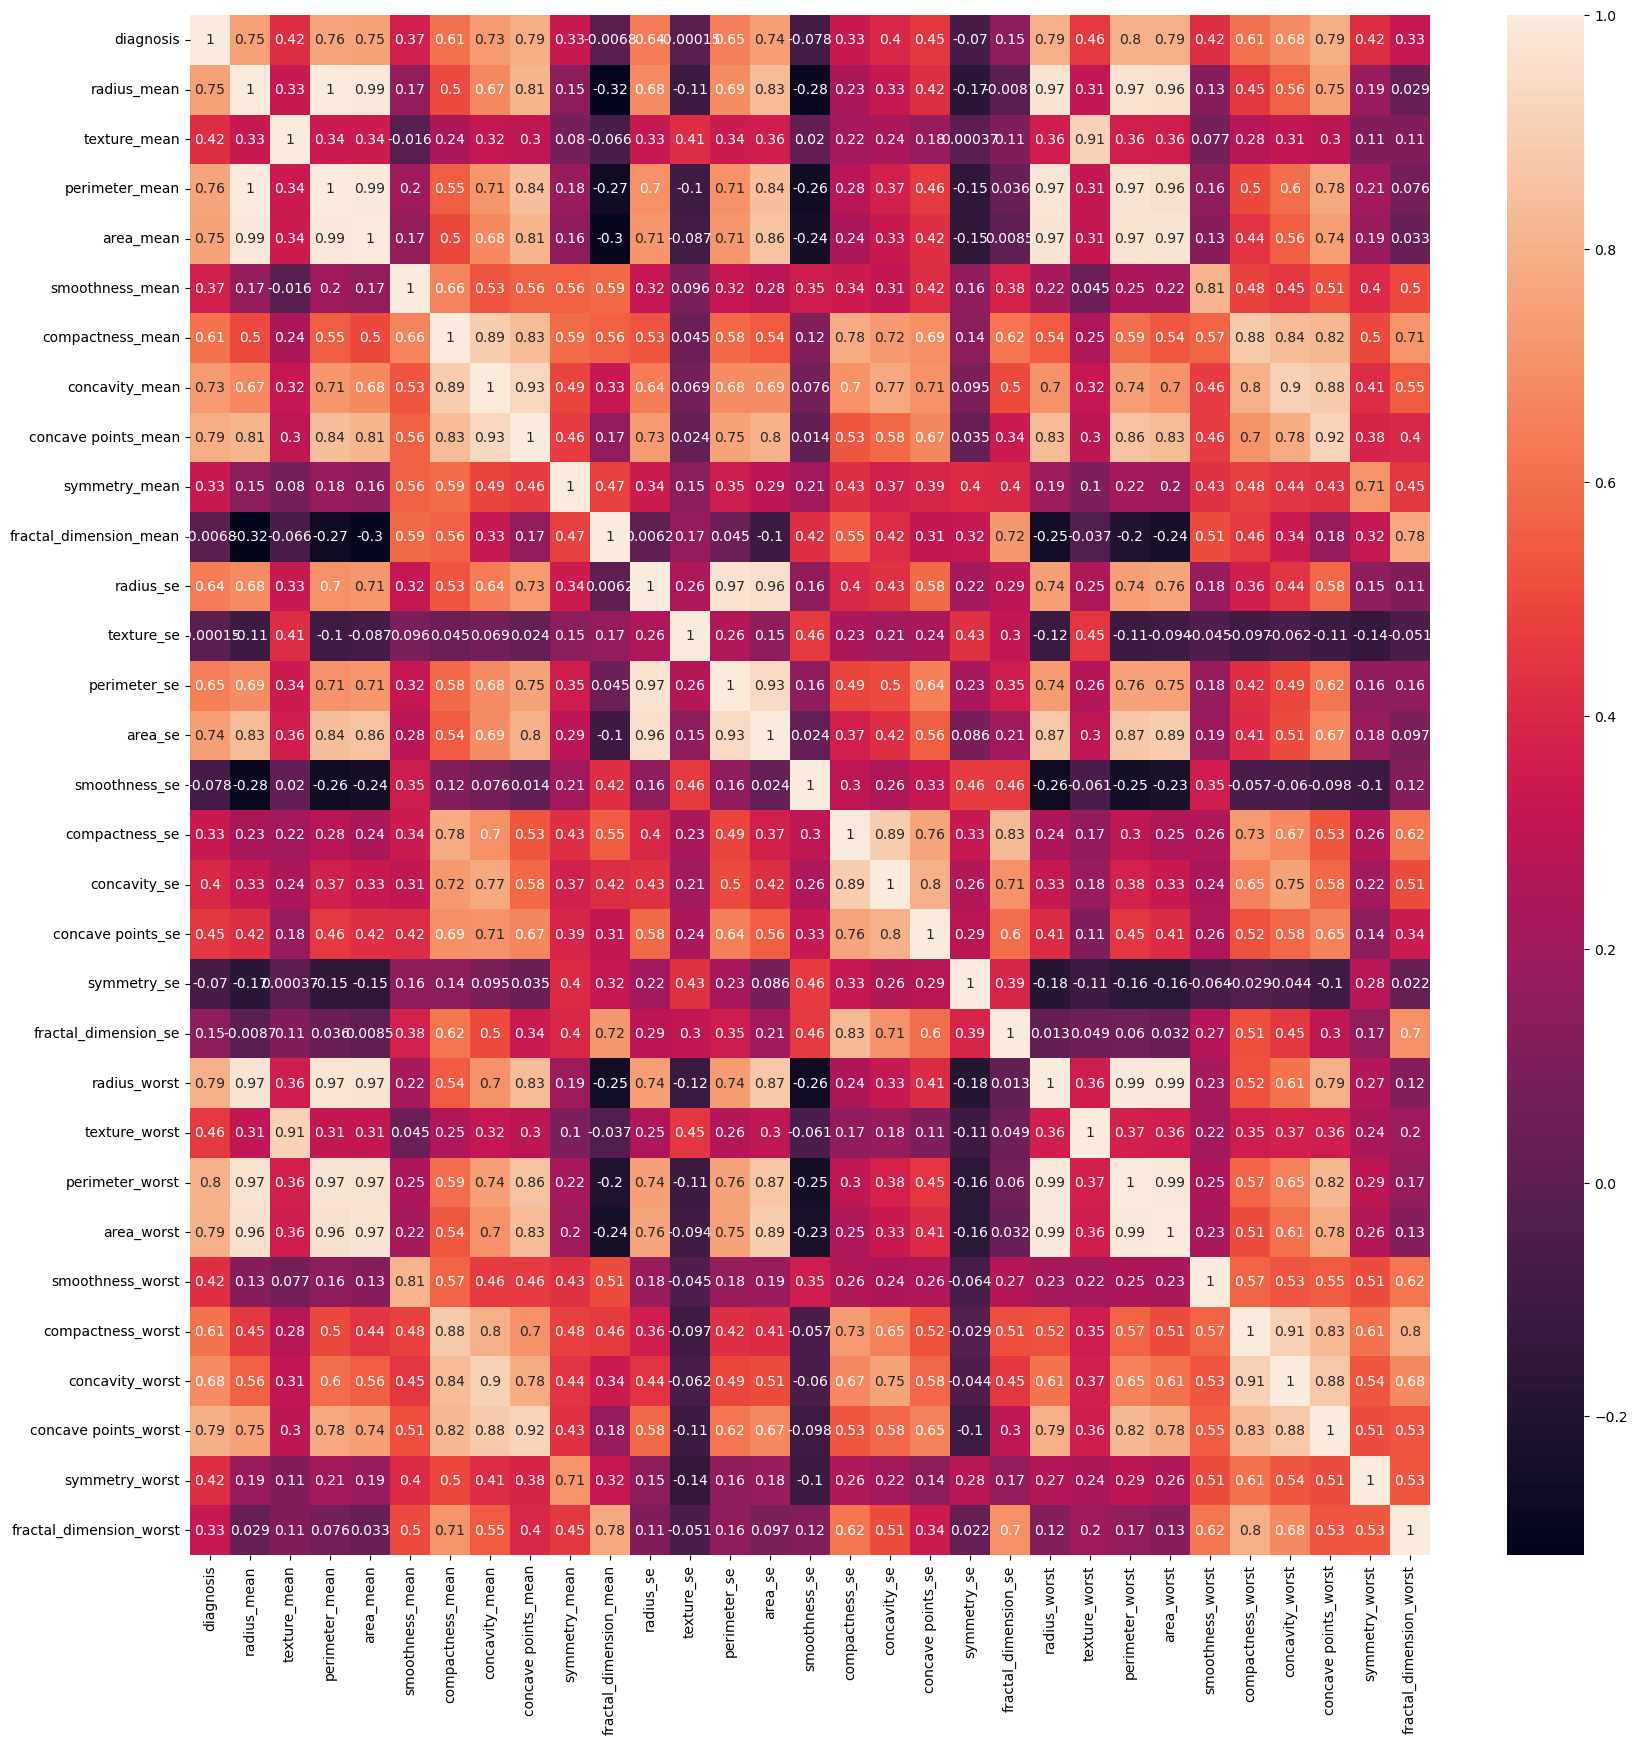

In [25]:
plt.figure(figsize=(20,20))
sns.heatmap(df.corr(),annot=True)
plt.show()

In [26]:
X=df.drop(['diagnosis','texture_worst','concave points_se','smoothness_worst','texture_mean','symmetry_worst','concavity_se','smoothness_mean','symmetry_mean','compactness_se','fractal_dimension_worst','fractal_dimension_se','smoothness_se','symmetry_se','fractal_dimension_mean','texture_se'],axis=1)
y=df['diagnosis']

In [27]:
#data transformation

In [28]:
SS=StandardScaler()
SS_X=SS.fit_transform(X)
x=pd.DataFrame(SS_X,columns=X.columns)
x.head()

,radius_mean,perimeter_mean,area_mean,compactness_mean,concavity_mean,concave points_mean,radius_se,perimeter_se,area_se,radius_worst,perimeter_worst,area_worst,compactness_worst,concavity_worst,concave points_worst
0,1.176800,1.357375,1.184085,2.541404,2.647422,2.620973,2.280613,2.343091,2.110995,2.006477,2.439568,2.287627,2.641905,2.246192,2.296076
1,1.949929,1.795991,2.249396,-0.498189,-0.000497,0.574944,0.780609,0.498609,1.611678,1.921384,1.631542,2.287627,-0.443388,-0.137634,1.087084
2,1.686226,1.670052,1.846217,1.148680,1.496076,2.110330,1.774057,1.345409,2.110995,1.611558,1.434234,1.807751,1.223448,0.920718,1.955000
3,-0.791983,-0.606410,-0.831485,2.541404,2.091997,1.506601,0.545151,0.532139,-0.318438,-0.277945,-0.245395,-0.593838,2.641905,2.119474,2.175786
4,1.866023,1.891531,2.154338,0.599453,1.504202,1.482665,1.831079,1.953934,2.110995,1.386825,1.424838,1.525780,-0.314469,0.665254,0.729259


In [29]:
#Data partition

In [30]:
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.3,random_state=42)

## *LOGISTIC REGRESSION*

In [31]:
#model selection

In [32]:
from sklearn.linear_model import LogisticRegression
log_model=LogisticRegression()

In [33]:
log_model.fit(x_train,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [34]:
y_pred_train_log=log_model.predict(x_train)
y_pred_test_log=log_model.predict(x_test)

In [35]:
print('Train accuracy ',round(accuracy_score(y_train,y_pred_train_log),2))
print('Train accuracy ',round(accuracy_score(y_test,y_pred_test_log),2))
#classification report
print(classification_report(y_test,y_pred_test_log))

Train accuracy  0.96
Train accuracy  0.95
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       108
           1       0.92      0.94      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



In [36]:
#cross validation
cv_scores=cross_val_score(log_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.9122807  0.93859649 0.96491228 0.96491228 0.96460177]
cross validation mean score:  0.9490607048594939


In [37]:
print('Train accuracy ',round(accuracy_score(y_train,y_pred_train_log),2))
print('Train accuracy ',round(accuracy_score(y_test,y_pred_test_log),2))
print('cross validation mean score: ',round(cv_scores.mean(),2))

Train accuracy  0.96
Train accuracy  0.95
cross validation mean score:  0.95


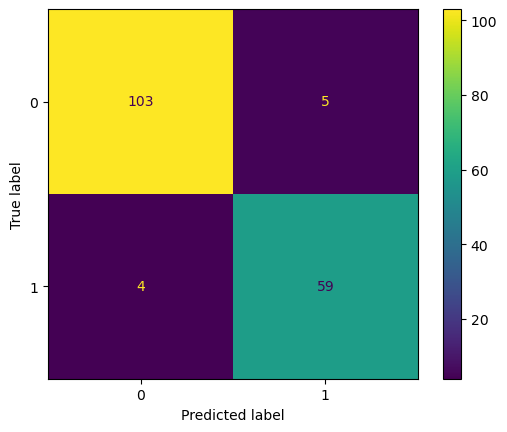

In [38]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_test_log)
plt.show()

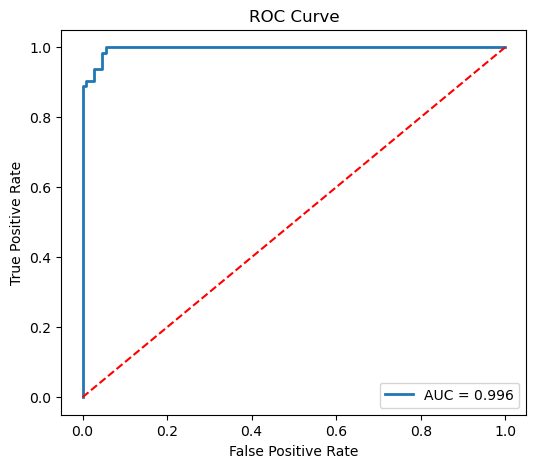

ROC AUC Score : 0.9958847736625513


In [39]:
y_prob = log_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *SVM*

In [40]:
from sklearn.svm import SVC
# Parameter Grid
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf','poly'],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'degree': [2,3,4]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=SVC(probability=True, random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit Model
grid_search.fit(x_train, y_train)

print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'C': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'linear'}
Best CV Score   : 0.9548417721518987


In [41]:
final_model = grid_search.best_estimator_

In [42]:
y_train_pred_svm = final_model.predict(x_train)
y_test_pred_svm = final_model.predict(x_test)

In [43]:
print("Training Accuracy :", accuracy_score(y_train, y_train_pred_svm))
print("Testing Accuracy  :", accuracy_score(y_test, y_test_pred_svm))
print(classification_report(y_test, y_test_pred_svm))

Training Accuracy : 0.9597989949748744
Testing Accuracy  : 0.9473684210526315
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       108
           1       0.92      0.94      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



In [44]:
#cross validation
cv_scores=cross_val_score(final_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.9122807  0.92982456 0.94736842 0.96491228 0.96460177]
cross validation mean score:  0.9437975469647568


In [45]:
print("Training Accuracy :", accuracy_score(y_train, y_train_pred_svm))
print("Testing Accuracy  :", accuracy_score(y_test, y_test_pred_svm))
print('cross validation mean score: ',cv_scores.mean())

Training Accuracy : 0.9597989949748744
Testing Accuracy  : 0.9473684210526315
cross validation mean score:  0.9437975469647568


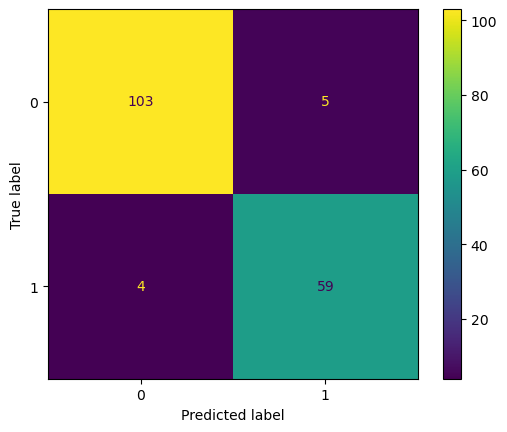

In [46]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_svm)
plt.show()

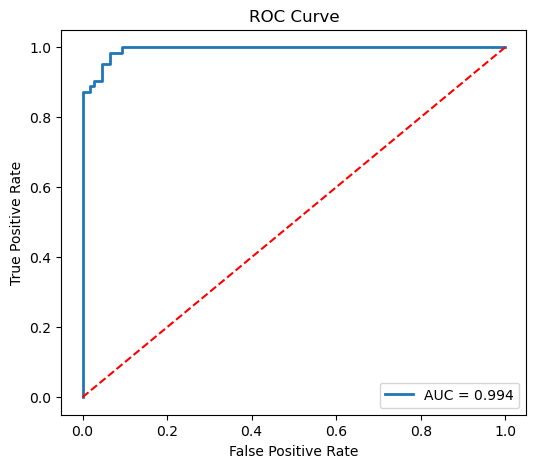

ROC AUC Score : 0.993533215755438


In [47]:
y_prob = final_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *DECISION TREE*

In [48]:
from sklearn.tree import DecisionTreeClassifier
# Parameter Grid
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': [None, 'sqrt', 'log2']
}

# Grid Search
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit Model
grid_search.fit(x_train, y_train)

print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'criterion': 'entropy', 'max_depth': 3, 'max_features': None, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV Score   : 0.9347151898734175


In [49]:
final_decision_model = grid_search.best_estimator_

In [50]:
y_train_pred_dec = final_decision_model.predict(x_train)
y_test_pred_dec = final_decision_model.predict(x_test)

In [51]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_dec),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_dec),2))
#classification report
print(classification_report(y_test,y_test_pred_dec))

Train accuracy  0.96
Train accuracy  0.94
              precision    recall  f1-score   support

           0       0.93      0.97      0.95       108
           1       0.95      0.87      0.91        63

    accuracy                           0.94       171
   macro avg       0.94      0.92      0.93       171
weighted avg       0.94      0.94      0.94       171



In [52]:
#cross validation
cv_scores=cross_val_score(final_decision_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.87719298 0.9122807  0.92105263 0.95614035 0.95575221]
cross validation mean score:  0.9244837758112094


In [53]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_dec),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_dec),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  0.96
Train accuracy  0.94
cross validation mean score:  0.9244837758112094


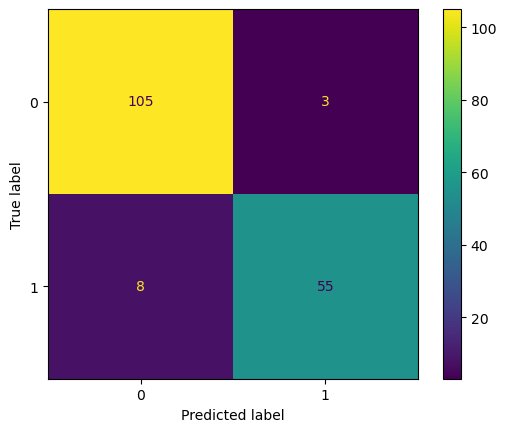

In [54]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_dec)
plt.show()

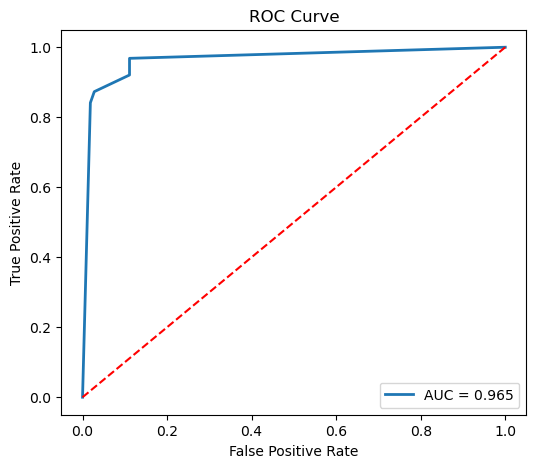

ROC AUC Score : 0.9652410346854791


In [55]:
y_prob = final_decision_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *BAGGING*

In [56]:
from sklearn.ensemble import BaggingClassifier
# Base Estimator
base_estimator = DecisionTreeClassifier(random_state=42)

# Parameter Grid
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_samples': [0.6, 0.8, 1.0],
    'max_features': [0.6, 0.8, 1.0],
    'bootstrap': [True, False]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=BaggingClassifier(
        estimator=base_estimator,
        random_state=42
    ),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit Grid Search
grid_search.fit(x_train, y_train)

print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'bootstrap': True, 'max_features': 0.6, 'max_samples': 0.8, 'n_estimators': 100}
Best CV Score   : 0.9421835443037974


In [57]:
final_bagging_model = grid_search.best_estimator_

In [58]:
y_train_pred_bag = final_bagging_model.predict(x_train)
y_test_pred_bag = final_bagging_model.predict(x_test)

In [59]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_bag),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_bag),2))
#classification report
print(classification_report(y_test,y_test_pred_bag))

Train accuracy  1.0
Train accuracy  0.96
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       108
           1       0.95      0.94      0.94        63

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



In [60]:
#cross validation
cv_scores=cross_val_score(final_bagging_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.90350877 0.9122807  0.97368421 0.93859649 0.96460177]
cross validation mean score:  0.9385343890700202


In [61]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_bag),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_bag),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  1.0
Train accuracy  0.96
cross validation mean score:  0.9385343890700202


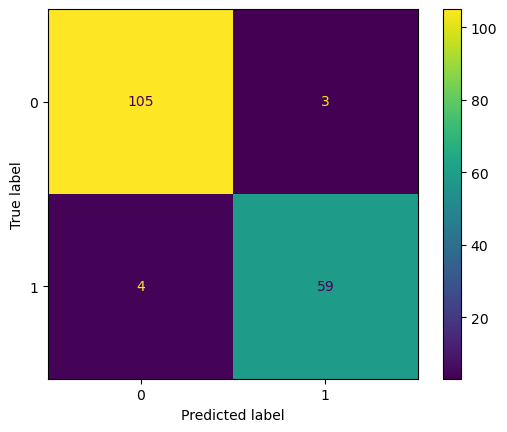

In [62]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_bag)
plt.show()

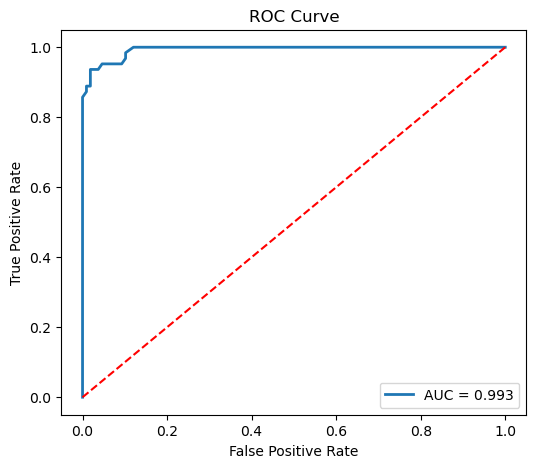

ROC AUC Score : 0.993312757201646


In [63]:
y_prob = final_bagging_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *RANDOM FOREST*

In [64]:
from sklearn.ensemble import RandomForestClassifier
# Parameter Grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}
# Grid Search
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit Model
grid_search.fit(x_train, y_train)

print("Best Parameters :", grid_search.best_params_)

print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Best CV Score   : 0.9422151898734177


In [65]:
final_random_model = grid_search.best_estimator_

In [66]:
y_train_pred_rand = final_random_model.predict(x_train)
y_test_pred_rand = final_random_model.predict(x_test)

In [67]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_rand),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_rand),2))
#classification report
print(classification_report(y_test,y_test_pred_rand))

Train accuracy  0.99
Train accuracy  0.96
              precision    recall  f1-score   support

           0       0.96      0.98      0.97       108
           1       0.97      0.94      0.95        63

    accuracy                           0.96       171
   macro avg       0.97      0.96      0.96       171
weighted avg       0.96      0.96      0.96       171



In [68]:
#cross validation
cv_scores=cross_val_score(final_random_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.90350877 0.92105263 0.98245614 0.95614035 0.96460177]
cross validation mean score:  0.9455519329296692


In [69]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_rand),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_rand),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  0.99
Train accuracy  0.96
cross validation mean score:  0.9455519329296692


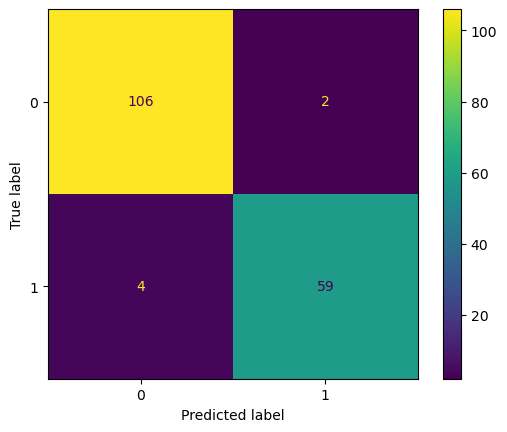

In [70]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_rand)
plt.show()

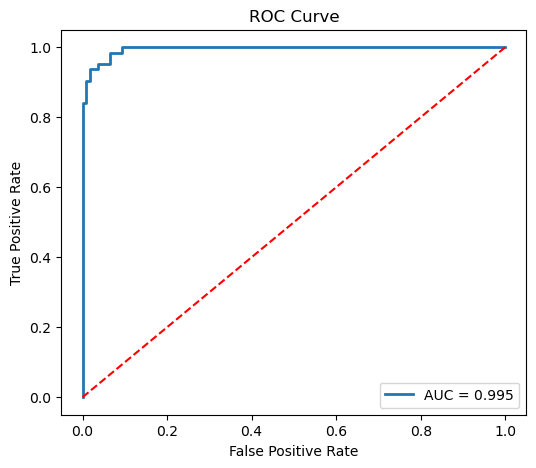

ROC AUC Score : 0.9947089947089948


In [71]:
y_prob = final_random_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *AdaBoost*

In [72]:
from sklearn.ensemble import AdaBoostClassifier
# Base Estimator
base_estimator = DecisionTreeClassifier(random_state=42)

# Parameter Grid
param_grid = {
    'estimator': [
        DecisionTreeClassifier(max_depth=1, random_state=42),
        DecisionTreeClassifier(max_depth=2, random_state=42),
        DecisionTreeClassifier(max_depth=3, random_state=42)
    ],
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5, 1.0]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=AdaBoostClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit Model
grid_search.fit(x_train, y_train)

print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'estimator': DecisionTreeClassifier(max_depth=1, random_state=42), 'learning_rate': 0.1, 'n_estimators': 100}
Best CV Score   : 0.9447151898734176


In [73]:
final_ada_model = grid_search.best_estimator_

In [74]:
y_train_pred_ada = final_ada_model.predict(x_train)
y_test_pred_ada = final_ada_model.predict(x_test)

In [75]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_ada),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_ada),2))
#classification report
print(classification_report(y_test,y_test_pred_ada))

Train accuracy  0.96
Train accuracy  0.94
              precision    recall  f1-score   support

           0       0.95      0.96      0.95       108
           1       0.93      0.90      0.92        63

    accuracy                           0.94       171
   macro avg       0.94      0.93      0.94       171
weighted avg       0.94      0.94      0.94       171



In [76]:
#cross validation
cv_scores=cross_val_score(final_ada_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.9122807  0.92982456 0.97368421 0.94736842 0.96460177]
cross validation mean score:  0.9455519329296692


In [77]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_ada),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_ada),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  0.96
Train accuracy  0.94
cross validation mean score:  0.9455519329296692


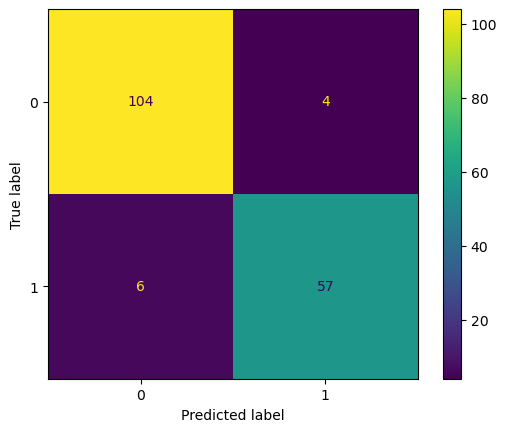

In [78]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_ada)
plt.show()

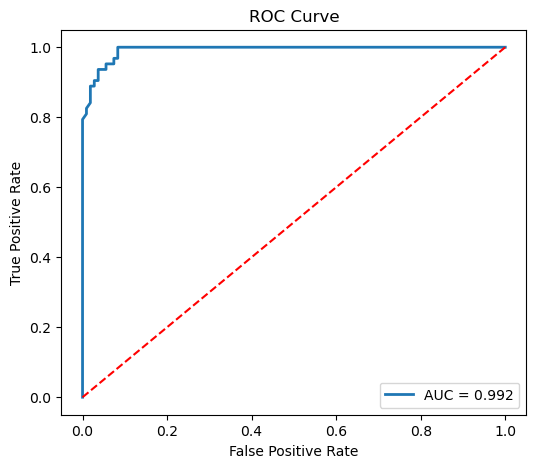

ROC AUC Score : 0.9923574368018813


In [79]:
y_prob = final_ada_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *GRADIENT BOOSTING*

In [80]:
from sklearn.ensemble import GradientBoostingClassifier
# Parameter Grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [2, 3, 4, 5],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'subsample': [0.8, 1.0],
    'max_features': ['sqrt', 'log2', None]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)

# Fit Model
grid_search.fit(x_train, y_train)

print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'learning_rate': 0.1, 'max_depth': 2, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100, 'subsample': 0.8}
Best CV Score   : 0.9497784810126582


In [81]:
final_gradient_model = grid_search.best_estimator_

In [82]:
y_train_pred_gradient = final_gradient_model.predict(x_train)
y_test_pred_gradient = final_gradient_model.predict(x_test)

In [83]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_gradient),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_gradient),2))
#classification report
print(classification_report(y_test,y_test_pred_gradient))

Train accuracy  1.0
Train accuracy  0.95
              precision    recall  f1-score   support

           0       0.96      0.95      0.96       108
           1       0.92      0.94      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



In [84]:
#cross validation
cv_scores=cross_val_score(final_gradient_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.9122807  0.92982456 0.99122807 0.94736842 0.96460177]
cross validation mean score:  0.9490607048594939


In [85]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_gradient),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_gradient),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  1.0
Train accuracy  0.95
cross validation mean score:  0.9490607048594939


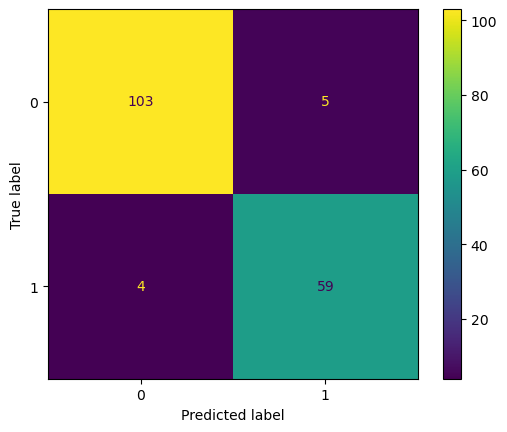

In [86]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_gradient)
plt.show()

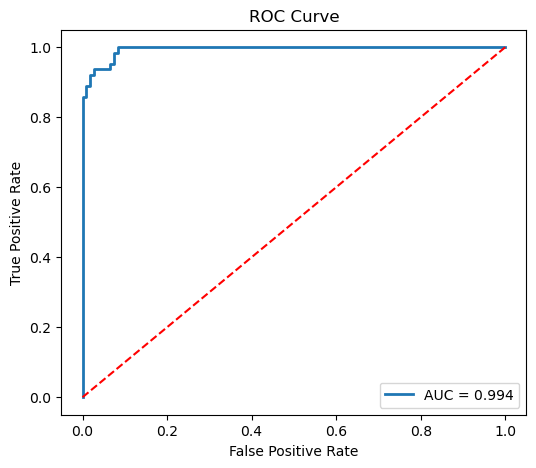

ROC AUC Score : 0.9939741328630217


In [87]:
y_prob = final_gradient_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *XGBoost*

In [88]:
from xgboost import XGBClassifier
# Parameter Grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'min_child_weight': [1, 3, 5],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'gamma': [0, 0.1, 0.2]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=XGBClassifier(
        objective='binary:logistic',
        eval_metric='logloss',
        random_state=42
    ),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
# Fit Model
grid_search.fit(x_train, y_train)
print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'colsample_bytree': 0.8, 'gamma': 0, 'learning_rate': 0.05, 'max_depth': 5, 'min_child_weight': 1, 'n_estimators': 300, 'subsample': 0.8}
Best CV Score   : 0.954778481012658


In [89]:
final_xg_model = grid_search.best_estimator_

In [90]:
y_train_pred_xg = final_xg_model.predict(x_train)
y_test_pred_xg = final_xg_model.predict(x_test)

In [91]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_xg),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_xg),2))
#classification report
print(classification_report(y_test,y_test_pred_xg))

Train accuracy  1.0
Train accuracy  0.95
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       108
           1       0.95      0.92      0.94        63

    accuracy                           0.95       171
   macro avg       0.95      0.95      0.95       171
weighted avg       0.95      0.95      0.95       171



In [92]:
#cross validation
cv_scores=cross_val_score(final_xg_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.90350877 0.92982456 0.98245614 0.92982456 0.95575221]
cross validation mean score:  0.9402732494954199


In [93]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_xg),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_xg),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  1.0
Train accuracy  0.95
cross validation mean score:  0.9402732494954199


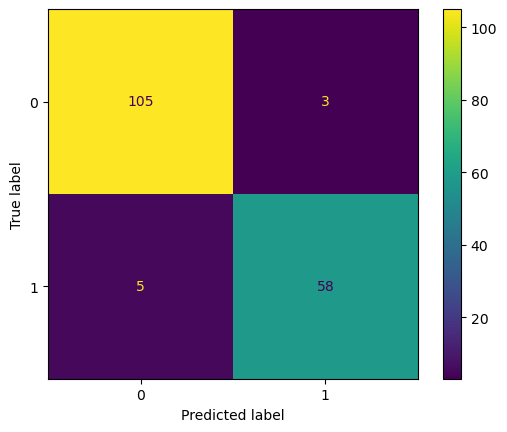

In [94]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_xg)
plt.show()

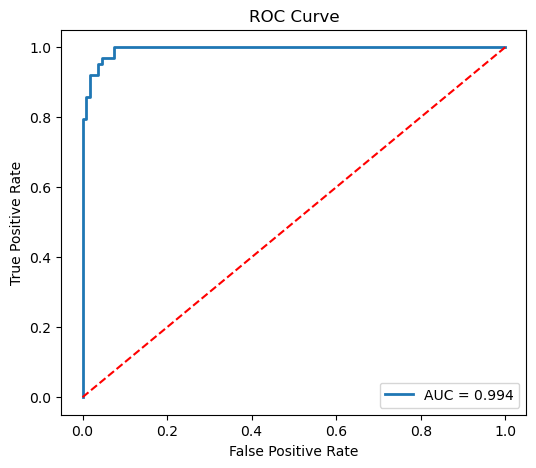

ROC AUC Score : 0.9939741328630218


In [95]:
y_prob = final_xg_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *LightGBM*

In [96]:
from lightgbm import LGBMClassifier
# Parameter Grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [-1, 3, 5, 7],
    'num_leaves': [15, 31, 63],
    'min_child_samples': [10, 20, 30],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Grid Search
grid_search = GridSearchCV(
    estimator=LGBMClassifier(
        objective='binary',
        random_state=42,
        verbose=-1
    ),
    param_grid=param_grid,
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
# Fit Model
grid_search.fit(x_train, y_train)
print("Best Parameters :", grid_search.best_params_)
print("Best CV Score   :", grid_search.best_score_)

Best Parameters : {'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 5, 'min_child_samples': 10, 'n_estimators': 300, 'num_leaves': 15, 'subsample': 0.8}
Best CV Score   : 0.9447151898734176


In [97]:
final_light_model = grid_search.best_estimator_

In [98]:
y_train_pred_light = final_light_model.predict(x_train)
y_test_pred_light = final_light_model.predict(x_test)

In [99]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_light),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_light),2))
#classification report
print(classification_report(y_test,y_test_pred_light))

Train accuracy  1.0
Train accuracy  0.96
              precision    recall  f1-score   support

           0       0.96      0.97      0.97       108
           1       0.95      0.94      0.94        63

    accuracy                           0.96       171
   macro avg       0.96      0.95      0.96       171
weighted avg       0.96      0.96      0.96       171



In [100]:
#cross validation
cv_scores=cross_val_score(final_light_model,x,y,cv=5)
print('cross validation score: ',cv_scores)
print('cross validation mean score: ',cv_scores.mean())

cross validation score:  [0.88596491 0.92982456 0.97368421 0.96491228 0.96460177]
cross validation mean score:  0.943797546964757


In [101]:
print('Train accuracy ',round(accuracy_score(y_train,y_train_pred_light),2))
print('Train accuracy ',round(accuracy_score(y_test,y_test_pred_light),2))
print('cross validation mean score: ',cv_scores.mean())

Train accuracy  1.0
Train accuracy  0.96
cross validation mean score:  0.943797546964757


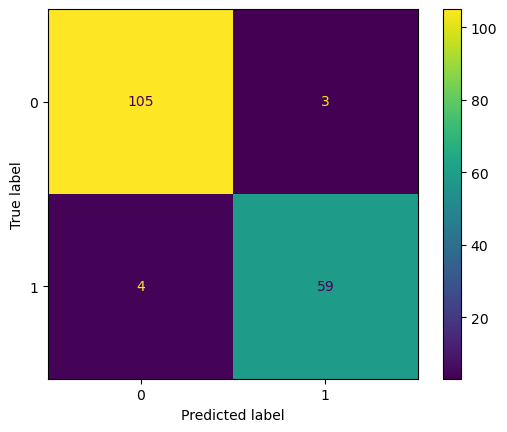

In [102]:
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred_light)
plt.show()

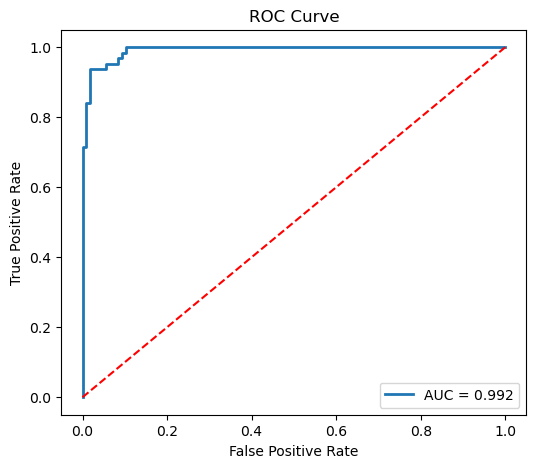

ROC AUC Score : 0.9917695473251029


In [103]:
y_prob = final_light_model.predict_proba(x_test)[:,1]
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {auc_score:.3f}")
plt.plot([0,1],[0,1],'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()
print("ROC AUC Score :", auc_score)

## *ANN*

In [104]:
import tensorflow as tf
tf.random.set_seed(42)

In [105]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
ann_model = Sequential()
# Input Layer + Hidden Layer 1
ann_model.add(Dense(64,
                    activation='relu',
                    input_shape=(x_train.shape[1],)))
# Hidden Layer 2
ann_model.add(Dense(32, activation='relu'))
# Hidden Layer 3
ann_model.add(Dense(16, activation='relu'))
# Output Layer
ann_model.add(Dense(1, activation='sigmoid'))

In [106]:
ann_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [107]:
history = ann_model.fit(x_train,y_train,epochs=50,batch_size=32,validation_split=0.2,verbose=1)

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 65ms/step - accuracy: 0.5252 - loss: 0.6039 - val_accuracy: 0.8250 - val_loss: 0.5525
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8994 - loss: 0.4964 - val_accuracy: 0.9250 - val_loss: 0.4515
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9214 - loss: 0.3895 - val_accuracy: 0.9375 - val_loss: 0.3315
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9308 - loss: 0.2831 - val_accuracy: 0.9500 - val_loss: 0.2253
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9277 - loss: 0.2070 - val_accuracy: 0.9500 - val_loss: 0.1634
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9403 - loss: 0.1710 - val_accuracy: 0.9500 - val_loss: 0.1363
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9371 - loss: 0.1571 - val_accuracy: 0.9500 - val_loss: 0.1251
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9371 - loss: 0.1494 - val_accuracy: 0.9500 - v

In [108]:
y_prob = ann_model.predict(x_test)
y_pred = (y_prob > 0.5).astype(int)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


In [109]:
print("Train Accuracy :", ann_model.evaluate(x_train, y_train, verbose=0)[1])
print("Test Accuracy :", accuracy_score(y_test, y_pred))
print("Precision :", precision_score(y_test, y_pred))
print("Recall :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))

Train Accuracy : 0.9874371886253357
Test Accuracy : 0.9473684210526315
Precision : 0.921875
Recall : 0.9365079365079365
F1 Score : 0.9291338582677166


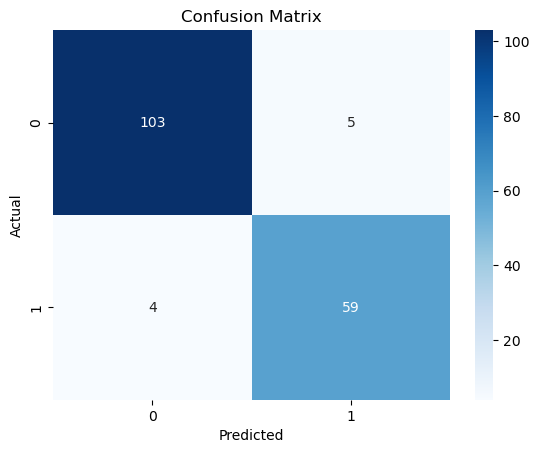

In [110]:
cm_ann = confusion_matrix(y_test, y_pred)
sns.heatmap(cm_ann,
            annot=True,
            fmt='d',
            cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [111]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.96      0.95      0.96       108
           1       0.92      0.94      0.93        63

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



In [117]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Store all trained models
models = {
    "Logistic Regression": final_model,
    "SVM": final_model,
    "Decision Tree": final_decision_model,
    "Bagging": final_bagging_model,
    "Random Forest": final_random_model,
    "AdaBoost": final_ada_model,
    "Gradient Boosting": final_gradient_model,
    "XGBoost": final_xg_model,
    "LightGBM": final_light_model
}

results = []

for name, model in models.items():

    # Predictions
    y_train_pred = model.predict(x_train)
    y_test_pred = model.predict(x_test)

    # Metrics
    train_acc = accuracy_score(y_train, y_train_pred)
    test_acc = accuracy_score(y_test, y_test_pred)
    precision = precision_score(y_test, y_test_pred)
    recall = recall_score(y_test, y_test_pred)
    f1 = f1_score(y_test, y_test_pred)

    results.append({
        "Model": name,
        "Train Accuracy": round(train_acc,4),
        "Test Accuracy": round(test_acc,4),
        "Precision": round(precision,4),
        "Recall": round(recall,4),
        "F1 Score": round(f1,4)
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="Test Accuracy",
    ascending=False
)

comparison_df.reset_index(drop=True, inplace=True)

comparison_df

,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.9899,0.9649,0.9672,0.9365,0.9516
1,Bagging,1.0000,0.9591,0.9516,0.9365,0.9440
2,LightGBM,1.0000,0.9591,0.9516,0.9365,0.9440
3,XGBoost,1.0000,0.9532,0.9508,0.9206,0.9355
4,Logistic Regression,0.9598,0.9474,0.9219,0.9365,0.9291
5,SVM,0.9598,0.9474,0.9219,0.9365,0.9291
6,Gradient Boosting,0.9975,0.9474,0.9219,0.9365,0.9291
7,AdaBoost,0.9623,0.9415,0.9344,0.9048,0.9194
8,Decision Tree,0.9623,0.9357,0.9483,0.8730,0.9091


In [118]:
best_model_name = comparison_df.iloc[0]["Model"]

print("Best Model :", best_model_name)

Best Model : Random Forest


In [119]:
best_model = models[best_model_name]

print(best_model)

RandomForestClassifier(min_samples_leaf=2, min_samples_split=5, random_state=42)


In [120]:
#saving the best model

In [121]:
import pickle
with open("model.pkl", "wb") as file:
    pickle.dump(final_random_model, file)

In [122]:
with open("scaler.pkl", "wb") as file:
    pickle.dump(SS, file)

In [123]:
feature_names = x.columns.tolist()

with open("features.pkl", "wb") as file:
    pickle.dump(feature_names, file)